In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# loading the dataset to a pandas dataframe
credit_card_data = pd.read_csv('/content/creditcard.csv')

In [ ]:
# first 5 rows of the dataset
credit_card_data.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0


In [ ]:
credit_card_data.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
45641,42436,-2.481639,-2.439949,0.363642,1.216827,2.572442,-1.264220,-0.443652,0.075853,0.073188,...,-0.039426,0.480591,1.779358,-0.756700,-0.161099,0.685617,0.223071,0.139619,0.00,0.0
45642,42436,1.223475,0.014944,0.471312,-0.038410,-0.566793,-0.867970,-0.058213,-0.144080,0.164904,...,-0.053292,-0.093680,0.106348,0.471407,0.135555,0.968336,-0.065171,0.005184,7.49,0.0
45643,42436,1.258657,0.421016,0.325437,0.684259,-0.292529,-1.052786,0.145228,-0.253567,-0.100521,...,-0.278029,-0.757417,0.119613,0.369393,0.246145,0.091553,-0.017156,0.032557,0.89,0.0
45644,42437,-0.500147,1.000770,1.809639,-0.114551,0.333865,-0.577076,1.062325,-0.513050,-0.048285,...,-0.193814,-0.161410,0.036965,0.400154,-0.802486,-0.076097,-0.214317,-0.229160,2.69,0.0
45645,42437,-0.652459,0.177290,1.955607,-1.879724,-0.368457,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# dataset information
credit_card_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45646 entries, 0 to 45645
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    45646 non-null  int64  
 1   V1      45646 non-null  float64
 2   V2      45646 non-null  float64
 3   V3      45646 non-null  float64
 4   V4      45646 non-null  float64
 5   V5      45646 non-null  float64
 6   V6      45645 non-null  float64
 7   V7      45645 non-null  float64
 8   V8      45645 non-null  float64
 9   V9      45645 non-null  float64
 10  V10     45645 non-null  float64
 11  V11     45645 non-null  float64
 12  V12     45645 non-null  float64
 13  V13     45645 non-null  float64
 14  V14     45645 non-null  float64
 15  V15     45645 non-null  float64
 16  V16     45645 non-null  float64
 17  V17     45645 non-null  float64
 18  V18     45645 non-null  float64
 19  V19     45645 non-null  float64
 20  V20     45645 non-null  float64
 21  V21     45645 non-null  float64
 22

In [ ]:
#checking the number of missing values in each column
credit_card_data.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,1
V7,1
V8,1
V9,1


In [ ]:
# distribution of legit transactions and fraudulent transactions
credit_card_data['Class'].value_counts()

,count
Class,
0.0,45503
1.0,142


In [ ]:
# separating the data for analysis
legit = credit_card_data[credit_card_data.Class == 0]
fraud = credit_card_data[credit_card_data.Class == 1]

In [ ]:
print(legit.shape)
print(fraud.shape)

(45503, 31)
(142, 31)


In [ ]:
# statistical measures of the data
legit.Amount.describe()

,Amount
count,45503.000000
mean,90.808470
std,240.322652
min,0.000000
25%,7.580000
50%,24.990000
75%,82.360000
max,7879.420000


In [ ]:
fraud.Amount.describe()

,Amount
count,142.000000
mean,97.592183
std,233.185192
min,0.000000
25%,1.000000
50%,8.370000
75%,99.990000
max,1809.680000


In [ ]:
# compare the values for both transactions
credit_card_data.groupby('Class').mean()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
Class,,,,,,,,,,,,,,,,,,,,,
0.0,27549.332857,-0.21371,0.011525,0.732168,0.173212,-0.230885,0.106122,-0.092498,0.041321,0.169777,...,0.046284,-0.029987,-0.108242,-0.038246,0.009637,0.136319,0.021863,0.003681,0.004547,90.808470
1.0,26193.556338,-7.87188,5.609155,-10.671851,6.067972,-5.862266,-2.315720,-8.269674,3.901566,-3.650345,...,0.486666,0.898581,-0.250143,-0.300033,-0.079930,0.257712,0.163858,0.596174,0.034797,97.592183


In [ ]:
legit_sample = legit.sample(n = 492)

In [ ]:
new_dataset = pd.concat([legit_sample, fraud], axis = 0)

In [ ]:
new_dataset.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
13894,24659,-0.632264,-0.350130,2.491137,-2.337413,-0.858949,-0.226690,-0.360311,-0.149494,-0.704331,...,-0.216418,0.197165,-0.217992,-0.004750,0.302543,-0.207374,0.125373,-0.100621,32.40,0.0
16881,28261,-1.772669,1.445227,0.592180,-1.954091,0.327147,0.710445,-0.310944,-1.107261,0.790122,...,1.319836,-0.943335,0.039270,-1.395513,-0.135549,0.848297,0.653027,0.336182,1.54,0.0
313,225,-0.608831,0.876837,2.495715,3.138674,0.161264,-0.107099,0.515854,-0.138226,-1.035070,...,-0.262866,-0.439237,-0.006775,0.717471,0.199742,0.072401,0.099756,-0.136524,35.11,0.0
28935,35243,-0.540039,0.906585,1.672109,0.019452,0.016941,-0.669060,0.573648,0.065403,-0.395359,...,-0.172574,-0.436121,0.069494,0.376832,-0.310597,0.081101,0.277769,0.122403,4.49,0.0
20095,30780,0.900561,-0.240829,0.151250,1.300538,-0.035389,0.383310,0.140166,0.108466,0.007572,...,0.007373,-0.054353,-0.229074,-0.275290,0.637445,-0.324094,0.013055,0.025019,135.00,0.0


In [ ]:
new_dataset.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
44091,41791,-7.222731,6.155773,-10.826460,4.180779,-6.123555,-3.114136,-6.895112,5.161516,-2.516477,...,0.912700,-0.630358,0.190887,-0.061263,0.379775,-0.266845,1.193695,0.257468,99.99,1.0
44223,41851,-19.139733,9.286847,-20.134992,7.818673,-15.652208,-1.668348,-21.340478,0.641900,-8.550110,...,-2.182692,0.520543,-0.760556,0.662767,-0.948454,0.121796,-3.381843,-1.256524,139.90,1.0
44270,41870,-20.906908,9.843153,-19.947726,6.155789,-15.142013,-2.239566,-21.234463,1.151795,-8.739670,...,-1.977196,0.652932,-0.519777,0.541702,-0.053861,0.112671,-3.765371,-1.071238,1.00,1.0
44556,41991,-4.566342,3.353451,-4.572028,3.616119,-2.493138,-1.090000,-5.551433,0.447783,-2.424414,...,2.674466,-0.020880,-0.302447,-0.086396,-0.516060,-0.295102,0.195985,0.141115,1.00,1.0
45203,42247,-2.524012,2.098152,-4.946075,6.456588,3.173921,-3.058806,-0.184710,-0.390420,-3.649812,...,0.027935,0.220366,0.976348,-0.290539,1.161002,0.663954,0.456023,-0.405682,1.00,1.0


In [ ]:
new_dataset['Class'].value_counts()

,count
Class,
0.0,492
1.0,142


In [ ]:
new_dataset.groupby('Class').mean()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
Class,,,,,,,,,,,,,,,,,,,,,
0.0,26572.386179,-0.18377,-0.025194,0.743708,0.142841,-0.219371,0.081021,-0.084049,0.108577,0.174300,...,0.072805,-0.020002,-0.127529,-0.047785,0.01479,0.126507,0.020124,-0.023311,0.008517,93.516199
1.0,26193.556338,-7.87188,5.609155,-10.671851,6.067972,-5.862266,-2.315720,-8.269674,3.901566,-3.650345,...,0.486666,0.898581,-0.250143,-0.300033,-0.07993,0.257712,0.163858,0.596174,0.034797,97.592183


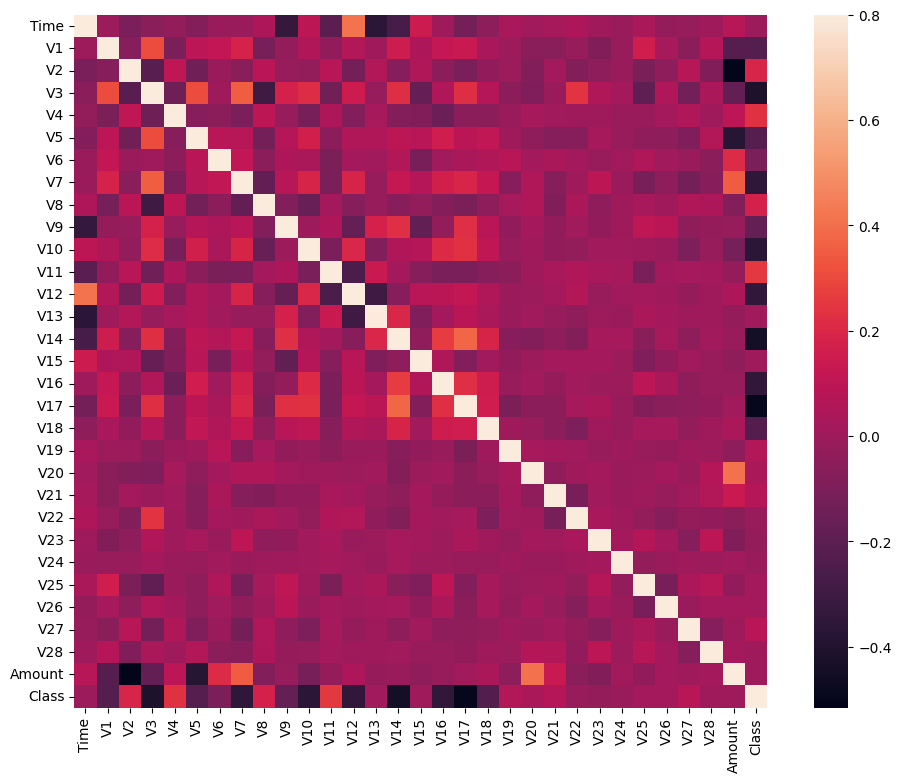

In [ ]:
# Correlation matrix
corrmat = credit_card_data.corr()
fig = plt.figure(figsize = (12, 9))
sns.heatmap(corrmat, vmax = .8, square = True)
plt.show()

In [ ]:
X = new_dataset.drop(columns = 'Class', axis = 1)
Y = new_dataset['Class']

In [ ]:
print(X)

        Time         V1        V2         V3        V4         V5        V6  \
13894  24659  -0.632264 -0.350130   2.491137 -2.337413  -0.858949 -0.226690   
16881  28261  -1.772669  1.445227   0.592180 -1.954091   0.327147  0.710445   
313      225  -0.608831  0.876837   2.495715  3.138674   0.161264 -0.107099   
28935  35243  -0.540039  0.906585   1.672109  0.019452   0.016941 -0.669060   
20095  30780   0.900561 -0.240829   0.151250  1.300538  -0.035389  0.383310   
...      ...        ...       ...        ...       ...        ...       ...   
44091  41791  -7.222731  6.155773 -10.826460  4.180779  -6.123555 -3.114136   
44223  41851 -19.139733  9.286847 -20.134992  7.818673 -15.652208 -1.668348   
44270  41870 -20.906908  9.843153 -19.947726  6.155789 -15.142013 -2.239566   
44556  41991  -4.566342  3.353451  -4.572028  3.616119  -2.493138 -1.090000   
45203  42247  -2.524012  2.098152  -4.946075  6.456588   3.173921 -3.058806   

              V7        V8        V9  ...       V20

In [ ]:
print(Y)

13894    0.0
16881    0.0
313      0.0
28935    0.0
20095    0.0
        ... 
44091    1.0
44223    1.0
44270    1.0
44556    1.0
45203    1.0
Name: Class, Length: 634, dtype: float64


In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size = 0.2, stratify=Y, random_state= 2)

In [ ]:
print(X.shape, X_train.shape, X_test.shape)

(634, 30) (507, 30) (127, 30)


In [ ]:
# Building the Random Forest Classifier (RANDOM FOREST)
from sklearn.ensemble import RandomForestClassifier
# random forest model creation
rfc = RandomForestClassifier()
rfc.fit(X_train, Y_train)
# predictions
yPred = rfc.predict(X_test)

In [ ]:
# Evaluating the classifier
# printing every score of the classifier
# scoring in anything
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import precision_score, recall_score
from sklearn.metrics import f1_score, matthews_corrcoef
from sklearn.metrics import confusion_matrix

n_outliers = len(fraud)
n_errors = (yPred != Y_test).sum()
print("The model used is Random Forest classifier")

acc = accuracy_score(Y_test, yPred)
print("The accuracy is {}".format(acc))

prec = precision_score(Y_test, yPred)
print("The precision is {}".format(prec))

rec = recall_score(Y_test, yPred)
print("The recall is {}".format(rec))

f1 = f1_score(Y_test, yPred)
print("The F1-Score is {}".format(f1))

MCC = matthews_corrcoef(Y_test, yPred)
print("The Matthews correlation coefficient is{}".format(MCC))

The model used is Random Forest classifier
The accuracy is 0.9763779527559056
The precision is 1.0
The recall is 0.8928571428571429
The F1-Score is 0.9433962264150944
The Matthews correlation coefficient is0.9309117244161565


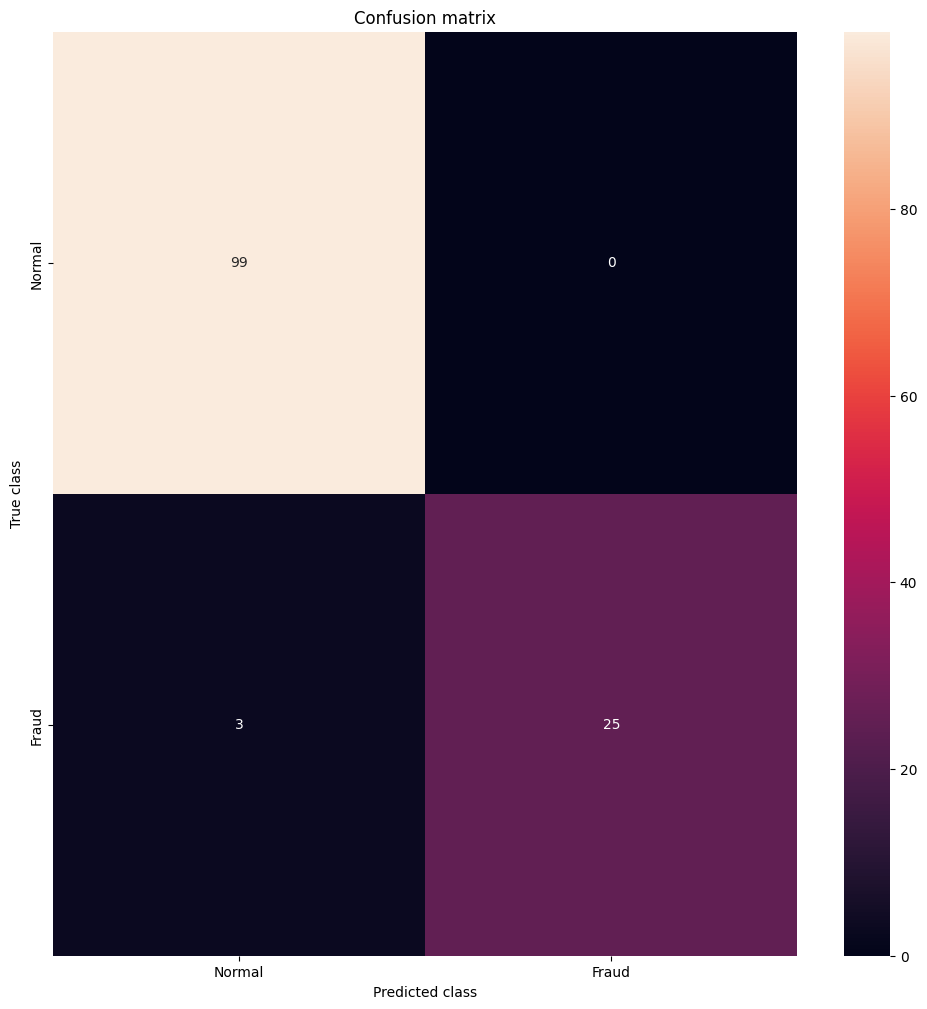

In [ ]:
# printing the confusion matrix
LABELS = ['Normal', 'Fraud']
conf_matrix = confusion_matrix(Y_test, yPred)
plt.figure(figsize =(12, 12))
sns.heatmap(conf_matrix, xticklabels = LABELS,
            yticklabels = LABELS, annot = True, fmt ="d");
plt.title("Confusion matrix")
plt.ylabel('True class')
plt.xlabel('Predicted class')
plt.show()